In [3]:
import pandas as pd
import numpy as np

# Load data yang sudah dibersihkan
df = pd.read_csv('/Users/macbook/Downloads/indonesia-financial-timeseries/data/clean_data.csv', parse_dates=['Date'], index_col='Date')

# Feature Engineering
df['IHSG_ret'] = df['IHSG'].pct_change()
df['USDIDR_ret'] = df['USDIDR'].pct_change()
df['OIL_ret'] = df['OIL'].pct_change()

df['VIX_lag1'] = df['VIX'].shift(1)
df['VIX_lag2'] = df['VIX'].shift(2)
df['USDIDR_ret_lag1'] = df['USDIDR_ret'].shift(1)

# Target: 1 jika IHSG besok naik, 0 jika turun
df['Target'] = np.where(df['IHSG_ret'].shift(-1) > 0, 1, 0)

# Hapus baris yang memiliki nilai NaN karena efek pergeseran (lag/shift)
df_model = df.dropna(subset=['VIX_lag2', 'USDIDR_ret_lag1', 'Target']).copy()

print(f"Total data siap dilatih: {len(df_model)} baris")

Total data siap dilatih: 4274 baris


In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

features = ['VIX_lag1', 'VIX_lag2', 'USDIDR_ret_lag1', 'IHSG_ret', 'OIL_ret']

X = df_model[features]
y = df_model['Target']

# Time-series split (80% Train, 20% Test)
split_index = int(len(df_model) * 0.8)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print(f"Periode Train : {X_train.index.min().date()} s/d {X_train.index.max().date()}")
print(f"Periode Test  : {X_test.index.min().date()} s/d {X_test.index.max().date()}")

# Model Random Forest
model = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
model.fit(X_train, y_train)

# Prediksi dan evaluasi
y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"\nAkurasi Model: {acc:.2%}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Feature Importance
importances = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
print("\nFeature Importance:")
print(importances)

Periode Train : 2010-01-06 s/d 2023-02-13
Periode Test  : 2023-02-14 s/d 2026-05-29

Akurasi Model: 50.99%

Classification Report:
              precision    recall  f1-score   support

           0       0.54      0.49      0.51       449
           1       0.49      0.54      0.51       406

    accuracy                           0.51       855
   macro avg       0.51      0.51      0.51       855
weighted avg       0.51      0.51      0.51       855


Feature Importance:
OIL_ret            0.322997
VIX_lag1           0.185136
VIX_lag2           0.182946
USDIDR_ret_lag1    0.159485
IHSG_ret           0.149437
dtype: float64


In [7]:
import xgboost as xgb
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import accuracy_score, f1_score

# Siapkan data (sama seperti sebelumnya)
features = ['VIX_lag1', 'VIX_lag2', 'USDIDR_ret_lag1', 'IHSG_ret', 'OIL_ret']
X = df_model[features]
y = df_model['Target']

# Inisialisasi TimeSeriesSplit (5 lipatan)
tscv = TimeSeriesSplit(n_splits=5)
model_xgb = xgb.XGBClassifier(
    n_estimators=100, 
    max_depth=3, 
    learning_rate=0.05, 
    random_state=42,
    eval_metric='logloss'
)

acc_scores = []
f1_scores = []

print("Memulai Walk-Forward Validation (TimeSeriesSplit)...")
for fold, (train_index, test_index) in enumerate(tscv.split(X)):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]
    
    # Train model
    model_xgb.fit(X_train, y_train)
    
    # Predict
    y_pred = model_xgb.predict(X_test)
    
    # Simpan metrik
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    acc_scores.append(acc)
    f1_scores.append(f1)
    
    print(f"Fold {fold+1} | Akurasi: {acc:.2%} | F1-Score: {f1:.2f}")

print(f"\nRata-rata Akurasi dari 5 Fold: {np.mean(acc_scores):.2%}")
print(f"Rata-rata F1-Score dari 5 Fold: {np.mean(f1_scores):.2f}")

# Feature Importance dari XGBoost
importances_xgb = pd.Series(model_xgb.feature_importances_, index=features).sort_values(ascending=False)
print("\nFeature Importance (XGBoost):")
print(importances_xgb)

Memulai Walk-Forward Validation (TimeSeriesSplit)...
Fold 1 | Akurasi: 52.11% | F1-Score: 0.50
Fold 2 | Akurasi: 51.12% | F1-Score: 0.57
Fold 3 | Akurasi: 50.28% | F1-Score: 0.57
Fold 4 | Akurasi: 50.00% | F1-Score: 0.56
Fold 5 | Akurasi: 49.16% | F1-Score: 0.50

Rata-rata Akurasi dari 5 Fold: 50.53%
Rata-rata F1-Score dari 5 Fold: 0.54

Feature Importance (XGBoost):
OIL_ret            0.298413
USDIDR_ret_lag1    0.208357
IHSG_ret           0.173913
VIX_lag1           0.162364
VIX_lag2           0.156953
dtype: float32


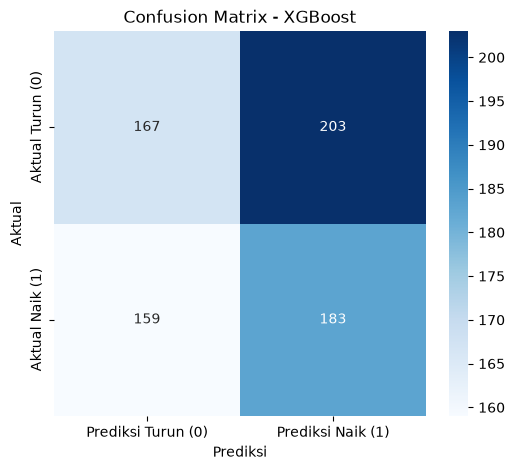

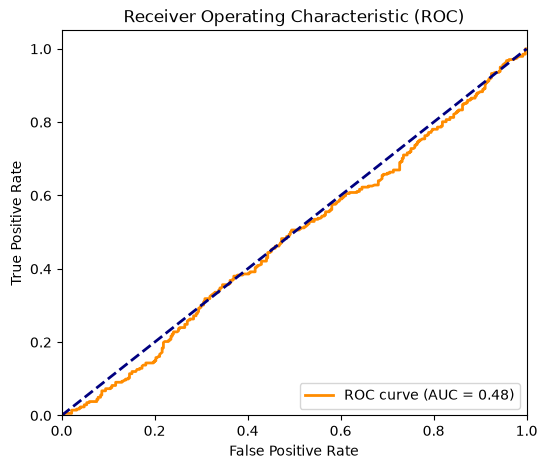

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

# Kita gunakan model_xgb yang terakhir dilatih di fold ke-5
# Atau Anda bisa melatih ulang model di seluruh data train
model_xgb.fit(X_train, y_train)
y_pred = model_xgb.predict(X_test)
y_prob = model_xgb.predict_proba(X_test)[:, 1]

# 1. Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Prediksi Turun (0)', 'Prediksi Naik (1)'],
            yticklabels=['Aktual Turun (0)', 'Aktual Naik (1)'])
plt.title('Confusion Matrix - XGBoost')
plt.ylabel('Aktual')
plt.xlabel('Prediksi')
plt.show()

# 2. Visualisasi ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

In [9]:
# Baseline Naive: Selalu menebak 1 (Naik)
y_pred_naive = np.ones(len(y_test))
acc_naive = accuracy_score(y_test, y_pred_naive)

# Bandingkan dengan model XGBoost
acc_xgb = accuracy_score(y_test, y_pred)

print("Perbandingan Akurasi:")
print(f"Naive Baseline (Selalu Tebak Naik) : {acc_naive:.2%}")
print(f"Model XGBoost                      : {acc_xgb:.2%}")

Perbandingan Akurasi:
Naive Baseline (Selalu Tebak Naik) : 48.03%
Model XGBoost                      : 49.16%


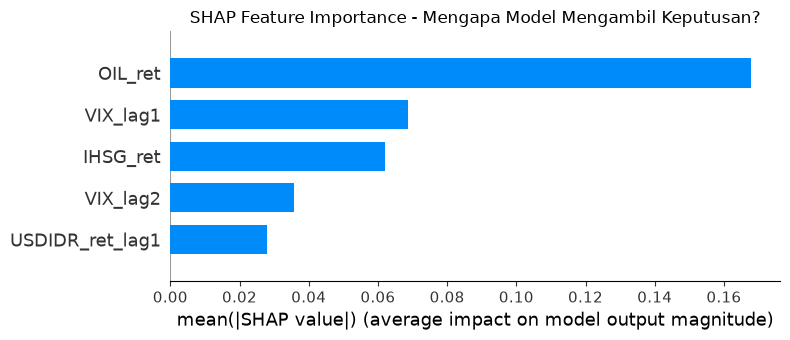

In [10]:
import shap

# Inisialisasi SHAP explainer untuk model tree (XGBoost)
explainer = shap.TreeExplainer(model_xgb)
shap_values = explainer.shap_values(X_test)

# Visualisasi ringkasan dampak fitur
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title('SHAP Feature Importance - Mengapa Model Mengambil Keputusan?')
plt.tight_layout()
plt.show()

In [11]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# 1. Prediksi dari model XGBoost kita
y_pred_xgb = model_xgb.predict(X_test)
acc_xgb = accuracy_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)

# 2. Prediksi Naive (selalu menebak 1/Naik)
y_pred_naive = np.ones(len(y_test))
acc_naive = accuracy_score(y_test, y_pred_naive)
f1_naive = f1_score(y_test, y_pred_naive)

print("=== PERBANDINGAN MODEL ===")
print(f"Naive Baseline (Selalu Tebak Naik) : Akurasi {acc_naive:.2%} | F1-Score {f1_naive:.2f}")
print(f"Model Machine Learning (XGBoost)   : Akurasi {acc_xgb:.2%} | F1-Score {f1_xgb:.2f}")

=== PERBANDINGAN MODEL ===
Naive Baseline (Selalu Tebak Naik) : Akurasi 48.03% | F1-Score 0.65
Model Machine Learning (XGBoost)   : Akurasi 49.16% | F1-Score 0.50


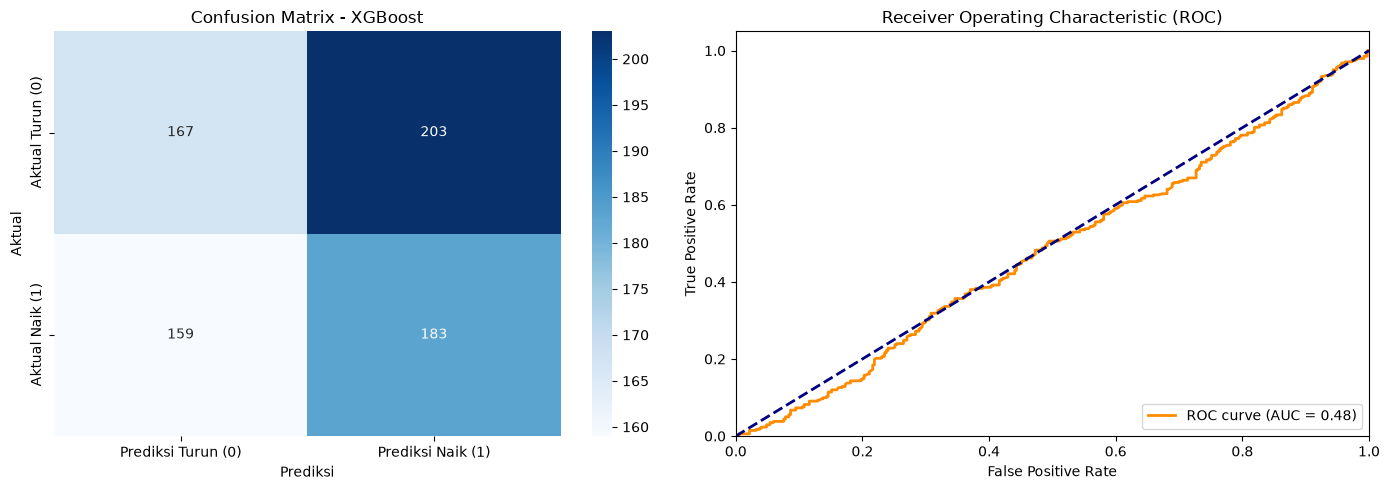

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

# Setup probabilitas untuk ROC-AUC
y_prob = model_xgb.predict_proba(X_test)[:, 1]

# --- Plot 1: Confusion Matrix ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Prediksi Turun (0)', 'Prediksi Naik (1)'],
            yticklabels=['Aktual Turun (0)', 'Aktual Naik (1)'])
axes[0].set_title('Confusion Matrix - XGBoost')
axes[0].set_ylabel('Aktual')
axes[0].set_xlabel('Prediksi')

# --- Plot 2: ROC Curve ---
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC)')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

In [13]:
# Tambahkan volatilitas 21 hari (1 bulan bursa)
df['IHSG_vol_21'] = df['IHSG_ret'].rolling(window=21).std()

# Masukkan ke dalam daftar fitur
features = ['VIX_lag1', 'VIX_lag2', 'USDIDR_ret_lag1', 'IHSG_ret', 'OIL_ret', 'IHSG_vol_21']

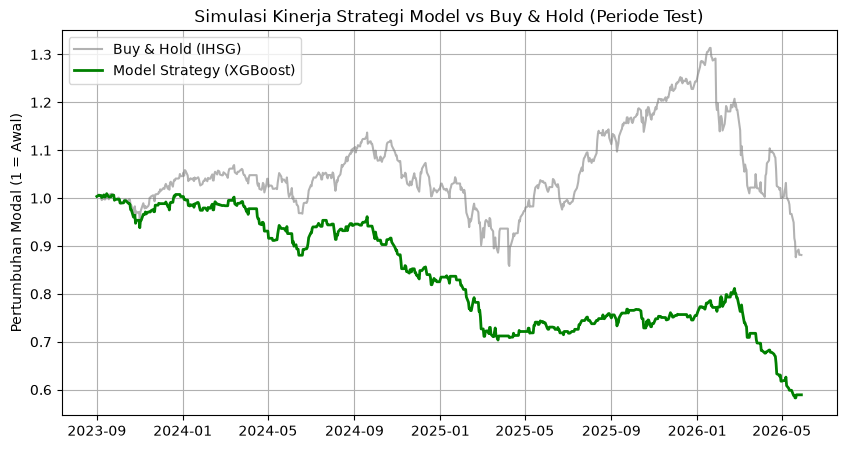

In [14]:
# Simulasi Strategi
# Return harian IHSG di data test
returns = df_model.loc[X_test.index, 'IHSG_ret']

# Strategi Model: Jika prediksi 1 (Naik), kita dapat return IHSG. Jika 0, return 0 (uang tunai).
strategy_returns = returns * y_pred_xgb

# Hitung akumulasi keuntungan (Cumulative Returns)
cum_market = (1 + returns).cumprod()
cum_strategy = (1 + strategy_returns).cumprod()

# Visualisasi
plt.figure(figsize=(10, 5))
plt.plot(cum_market, label="Buy & Hold (IHSG)", color='gray', alpha=0.6)
plt.plot(cum_strategy, label="Model Strategy (XGBoost)", color='green', linewidth=2)
plt.title("Simulasi Kinerja Strategi Model vs Buy & Hold (Periode Test)")
plt.ylabel("Pertumbuhan Modal (1 = Awal)")
plt.legend()
plt.grid(True)
plt.show()